In [1]:
import torch
import os
from pathlib import Path

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU in Colab.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [6]:
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/kitti.zip -O kitti.zip

In [7]:
import zipfile
from pathlib import Path

zip_path = Path("kitti.zip")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("kitti_data")

print("Extraction completed!")

Extraction completed!


In [8]:
from pathlib import Path

data_dir = Path("kitti_data")

for path in list(data_dir.rglob("*"))[:30]:
    print(path)

kitti_data/kitti.yaml
kitti_data/images
kitti_data/labels
kitti_data/images/val
kitti_data/images/train
kitti_data/labels/val
kitti_data/labels/train
kitti_data/labels/val/006720.txt
kitti_data/labels/val/002806.txt
kitti_data/labels/val/006954.txt
kitti_data/labels/val/001865.txt
kitti_data/labels/val/001832.txt
kitti_data/labels/val/004473.txt
kitti_data/labels/val/006200.txt
kitti_data/labels/val/004591.txt
kitti_data/labels/val/002522.txt
kitti_data/labels/val/002227.txt
kitti_data/labels/val/005105.txt
kitti_data/labels/val/003928.txt
kitti_data/labels/val/002421.txt
kitti_data/labels/val/004317.txt
kitti_data/labels/val/003745.txt
kitti_data/labels/val/002514.txt
kitti_data/labels/val/005418.txt
kitti_data/labels/val/002772.txt
kitti_data/labels/val/002341.txt
kitti_data/labels/val/004302.txt
kitti_data/labels/val/002617.txt
kitti_data/labels/val/002013.txt
kitti_data/labels/val/004368.txt


In [9]:
from pathlib import Path
import yaml
from collections import Counter

data_dir = Path("/content/kitti_data")
yaml_path = data_dir / "kitti.yaml"

with open(yaml_path, "r") as f:
    kitti_config = yaml.safe_load(f)

print("Dataset YAML:")
print(kitti_config)

print("\nNumber of classes:", kitti_config.get("nc", len(kitti_config.get("names", []))))
print("Class names:", kitti_config.get("names"))

for split in ["train", "val"]:
    label_dir = data_dir / "labels" / split
    label_files = list(label_dir.glob("*.txt"))
    class_counts = Counter()

    for file in label_files:
        for line in file.read_text().splitlines():
            values = line.split()
            if values:
                class_counts[int(float(values[0]))] += 1

    print(f"\n{split.upper()}:")
    print("Label files:", len(label_files))
    print("Object counts by class ID:", dict(sorted(class_counts.items())))

Dataset YAML:
{'path': 'kitti', 'train': 'images/train', 'val': 'images/val', 'names': {0: 'car', 1: 'van', 2: 'truck', 3: 'pedestrian', 4: 'Person_sitting', 5: 'cyclist', 6: 'tram', 7: 'misc'}, 'download': 'https://github.com/ultralytics/assets/releases/download/v0.0.0/kitti.zip'}

Number of classes: 8
Class names: {0: 'car', 1: 'van', 2: 'truck', 3: 'pedestrian', 4: 'Person_sitting', 5: 'cyclist', 6: 'tram', 7: 'misc'}

TRAIN:
Label files: 5985
Object counts by class ID: {0: 23026, 1: 2359, 2: 871, 3: 3566, 4: 186, 5: 1275, 6: 394, 7: 765}

VAL:
Label files: 1496
Object counts by class ID: {0: 5716, 1: 555, 2: 223, 3: 921, 4: 36, 5: 352, 6: 117, 7: 208}


In [10]:
from pathlib import Path
import yaml

data_dir = Path("/content/kitti_data")

yolo_config = {
    "path": str(data_dir),
    "train": "images/train",
    "val": "images/val",
    "names": {
        0: "car",
        1: "van",
        2: "truck",
        3: "pedestrian",
        4: "Person_sitting",
        5: "cyclist",
        6: "tram",
        7: "misc",
    },
}

yaml_path = Path("/content/kitti_8classes.yaml")

with open(yaml_path, "w") as f:
    yaml.safe_dump(yolo_config, f, sort_keys=False)

print(yaml_path.read_text())

path: /content/kitti_data
train: images/train
val: images/val
names:
  0: car
  1: van
  2: truck
  3: pedestrian
  4: Person_sitting
  5: cyclist
  6: tram
  7: misc



In [11]:
from pathlib import Path

data_dir = Path("/content/kitti_data")

print("Train images:", len(list((data_dir / "images/train").glob("*.png"))))
print("Train labels:", len(list((data_dir / "labels/train").glob("*.txt"))))

print("Validation images:", len(list((data_dir / "images/val").glob("*.png"))))
print("Validation labels:", len(list((data_dir / "labels/val").glob("*.txt"))))

Train images: 5985
Train labels: 5985
Validation images: 1496
Validation labels: 1496


In [12]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/kitti_8classes.yaml",
    epochs=5,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    name="kitti_8classes"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/kitti_8classes.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fr

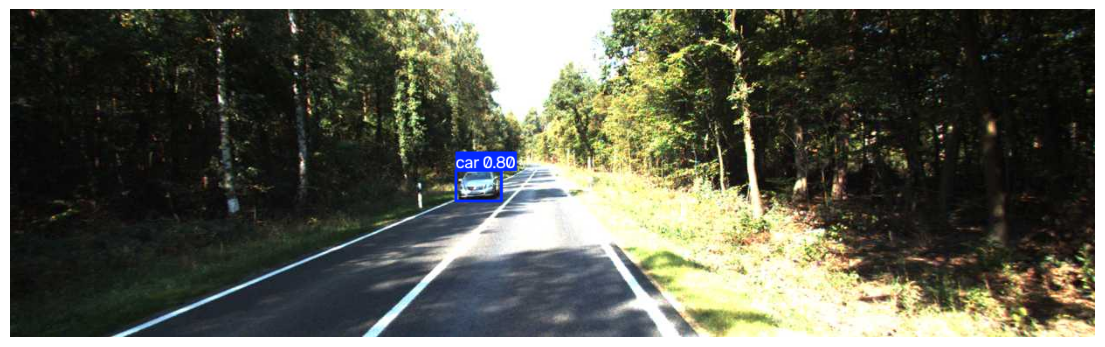

In [13]:
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt

model = YOLO(
    "/content/runs/detect/kitti_8classes/weights/best.pt"
)

image_path = next(
    Path("/content/kitti_data/images/val").glob("*.png")
)

results = model.predict(
    source=str(image_path),
    conf=0.25,
    verbose=False
)

plt.figure(figsize=(14, 6))
plt.imshow(results[0].plot()[..., ::-1])
plt.axis("off")
plt.show()

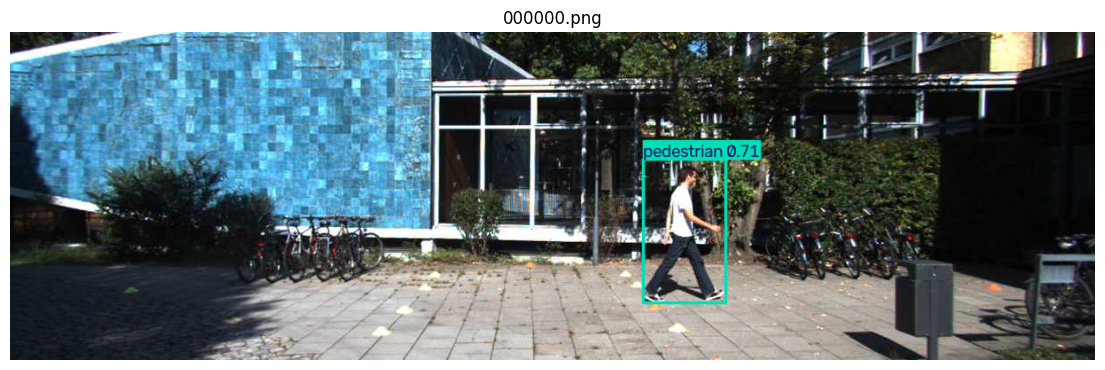

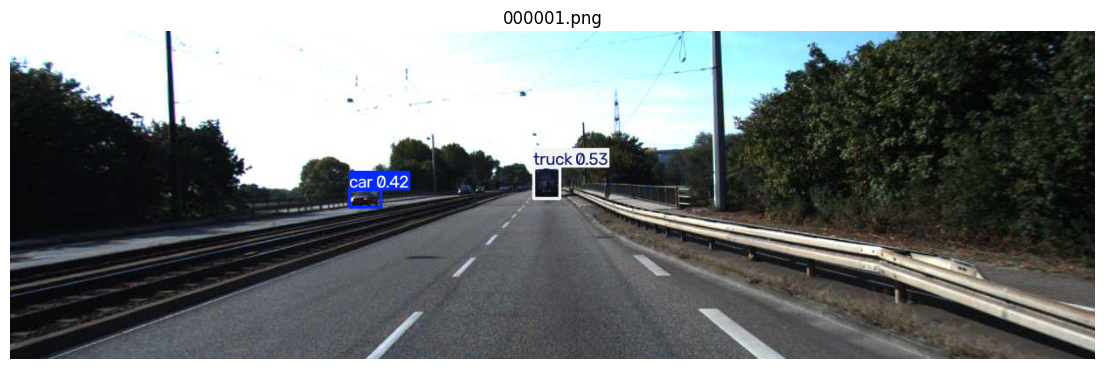

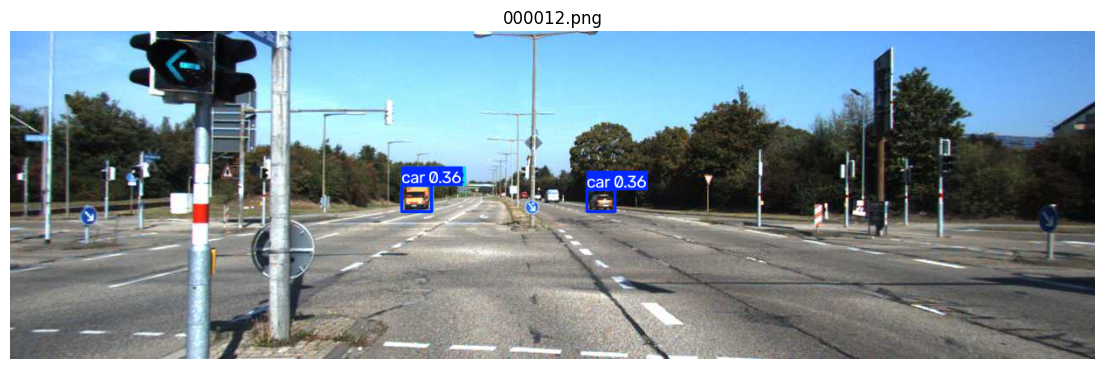

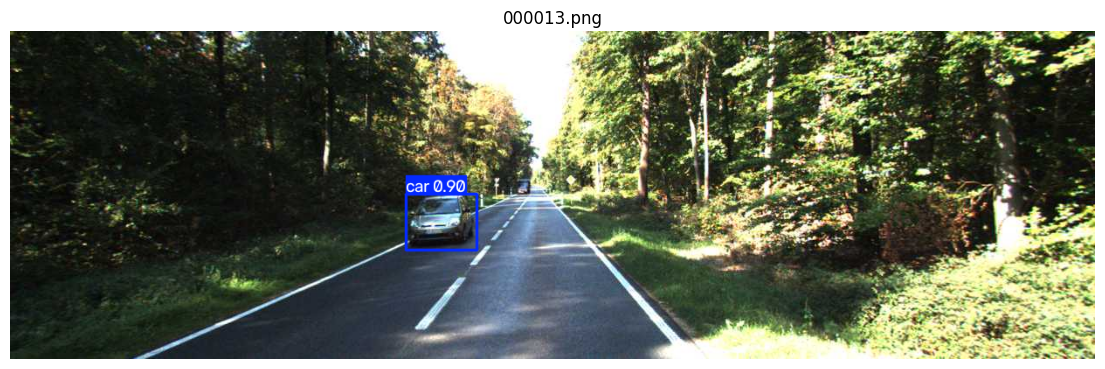

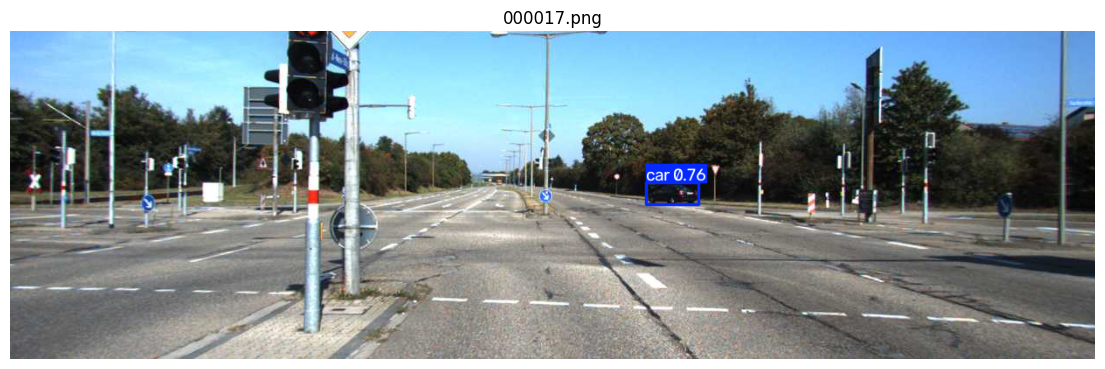

In [14]:
from pathlib import Path
import matplotlib.pyplot as plt

image_paths = sorted(
    Path("/content/kitti_data/images/val").glob("*.png")
)[:5]

for image_path in image_paths:
    results = model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )

    plt.figure(figsize=(14, 6))
    plt.imshow(results[0].plot()[..., ::-1])
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

In [15]:
from ultralytics import YOLO

model = YOLO(
    "/content/runs/detect/kitti_8classes/weights/last.pt"
)

results = model.train(
    data="/content/kitti_8classes.yaml",
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    name="kitti_8classes_finetune"
)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/kitti_8classes.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/kitti_8classes/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=kitti_8classes_finet

In [21]:
from ultralytics import YOLO

model = YOLO(
    "/content/runs/detect/kitti_8classes_finetune/weights/last.pt"
)

results = model.train(
    data="/content/kitti_8classes.yaml",
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    name="kitti_8classes_finetune2"
)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/kitti_8classes.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/kitti_8classes_finetune/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=kitti_8clas

In [22]:
from ultralytics import YOLO
from IPython.display import display
from google.colab import files
import os
import glob
import shutil

# 1. Load best model
model = YOLO(
    "/content/runs/detect/kitti_8classes_finetune2/weights/best.pt"
)

# 2. Evaluate on validation set
metrics = model.val(
    data="/content/kitti_8classes.yaml",
    split="val",
    imgsz=640,
    batch=8,
    device=0
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

# 3. Predict on all validation images and save bounding boxes
output_dir = "/content/kitti_validation_predictions"

model.predict(
    source="/content/kitti_data/images/val",
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content",
    name="kitti_validation_predictions",
    exist_ok=True
)

# 4. Create ZIP folder
zip_path = shutil.make_archive(
    "/content/kitti_validation_predictions",
    "zip",
    output_dir
)

print("ZIP created:", zip_path)

# 5. Download
files.download(zip_path)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,752 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1549.1±586.1 MB/s, size: 52.1 KB)
val: Scanning /content/kitti_data/labels/val.cache... 1496 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1496/1496 133.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 187/187 14.2it/s 13.2s
                   all       1496       8128      0.806      0.617      0.723      0.462
                   car       1322       5716      0.916       0.79      0.904      0.655
                   van        419        555       0.81      0.623      0.721      0.529
                 truck        212        223      0.948      0.811      0.894      0.675
            pedestrian        377        921      0.764      0.497      0.623      0.324
        Person_sitting         17   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from google.colab import drive
import shutil
import os

# Connect Google Drive
drive.mount('/content/drive')

# Source folder
folder = "/content/kitti_validation_predictions"

# Destination in Google Drive
drive_folder = "/content/drive/MyDrive/KITTI_Results"
os.makedirs(drive_folder, exist_ok=True)

# Create ZIP directly in Google Drive
zip_path = os.path.join(drive_folder, "kitti_validation_predictions.zip")

shutil.make_archive(
    zip_path.replace(".zip", ""),
    "zip",
    folder
)

print("Saved successfully:", zip_path)

Mounted at /content/drive
Saved successfully: /content/drive/MyDrive/KITTI_Results/kitti_validation_predictions.zip
